# TUSZ raw vs. preprocessed data inspection
Run the cells top to bottom. Edit only the **Config** cell.

In [ ]:
# ===================== CONFIG (edit this) =====================
import os, re, glob, random, collections
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import mne
from tqdm.auto import tqdm

mne.set_log_level("ERROR")
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 50)

ROOT = "/home/asifislam/Downloads/Datasets/TUHEEG/Seizure/v2.0.6/edf"   # raw edf root (train/ dev/ eval/)
PROCESSED = os.path.join(ROOT, "processed_tusz_multiclass")                     # preprocessed output (train/ val/ test/)
TASK = "multiclass"            # "binary" or "multiclass" (decides which annotation file / label names are used)
FS = 200                       # must match --fs used in preprocessing
DURATION = 5                   # must match --duration
SCALE_FACTOR = 1e4             # same as the dataloader
CLIP = 100                     # same as `clip` in the yaml
SEIZURE_TYPES = ["fnsz", "gnsz", "cpsz", "absz", "spsz", "tcsz", "tnsz", "mysz"]   # must match --classes order

COMPUTE_RAW_HEADERS = True     # reads every EDF header (duration, sfreq, channels). Set False for a fast run
MAX_HEADER_FILES = None        # e.g. 300 to only look at a sample of each split
SEED = 0

SPLIT_DIRS = {"train": "train", "val": "dev", "test": "eval"}  
ANN_EXT = {"binary": ".csv_bi", "multiclass": ".csv"}[TASK]
CLASS_NAMES = ["bckg", "seiz"] if TASK == "binary" else ["bckg"] + SEIZURE_TYPES
N_CLASSES = len(CLASS_NAMES)

ELECTRODES = ['FP1-F7','F7-T3','T3-T5','T5-O1','FP2-F8','F8-T4','T4-T6','T6-O2',
              'FP1-F3','F3-C3','C3-P3','P3-O1','FP2-F4','F4-C4','C4-P4','P4-O2']
NEEDED = sorted({e for p in ELECTRODES for e in p.split("-")})
CH_RE = re.compile(r"^EEG\s+([A-Z0-9]+)-(REF|LE|AR)", re.IGNORECASE)

random.seed(SEED); np.random.seed(SEED)
print("Task:", TASK, "| classes:", dict(enumerate(CLASS_NAMES)))
print("Raw root exists:", os.path.isdir(ROOT), "| processed exists:", os.path.isdir(PROCESSED))

Task: multiclass | classes: {0: 'bckg', 1: 'fnsz', 2: 'gnsz', 3: 'cpsz', 4: 'absz', 5: 'spsz', 6: 'tcsz', 7: 'tnsz', 8: 'mysz'}
Raw root exists: True | processed exists: True


## 1. Raw dataset: files, patients, sessions, size

In [6]:
def walk_split(split_root):
    edfs, anns_bi, anns_csv = [], [], []
    for dp, dn, fs in os.walk(split_root):
        for f in fs:
            p = os.path.join(dp, f)
            if f.endswith(".edf"): edfs.append(p)
            elif f.endswith(".csv_bi"): anns_bi.append(p)
            elif f.endswith(".csv"): anns_csv.append(p)
    return sorted(edfs), anns_bi, anns_csv

RAW = {}
rows = []
for split, folder in SPLIT_DIRS.items():
    sr = os.path.join(ROOT, folder)
    if not os.path.isdir(sr):
        print("MISSING:", sr); continue
    edfs, bi, csv = walk_split(sr)
    RAW[split] = edfs
    rel = [os.path.relpath(p, sr).split(os.sep) for p in edfs]
    rows.append(dict(split=split, folder=folder, edf_files=len(edfs), csv_bi=len(bi), csv=len(csv),
                     patients=len({r[0] for r in rel}), sessions=len({tuple(r[:2]) for r in rel}),
                     size_GB=round(sum(os.path.getsize(p) for p in edfs) / 1e9, 2)))
raw_summary = pd.DataFrame(rows).set_index("split")
raw_summary.loc["TOTAL"] = raw_summary.sum(numeric_only=True)
display(raw_summary)

# folder structure example
ex = RAW["train"][0]
print("Example path (relative to root):\n ", os.path.relpath(ex, ROOT))
print("Montage folders seen in train:", collections.Counter(p.split(os.sep)[-2] for p in RAW["train"]).most_common())

,folder,edf_files,csv_bi,csv,patients,sessions,size_GB
split,,,,,,,
train,train,5057.0,5057.0,5057.0,579.0,1175.0,55.33
val,dev,2203.0,2203.0,2203.0,53.0,342.0,22.18
test,eval,880.0,880.0,880.0,43.0,126.0,7.15
TOTAL,NaN,8140.0,8140.0,8140.0,675.0,1643.0,84.66


Example path (relative to root):
  train/aaaaaaac/s001_2002/02_tcp_le/aaaaaaac_s001_t000.edf
Montage folders seen in train: [('01_tcp_ar', 3412), ('03_tcp_ar_a', 1123), ('02_tcp_le', 522)]


## 2. Raw EDF headers: duration, sampling rate, channel availability

In [7]:
def header_info(p):
    try:
        raw = mne.io.read_raw_edf(p, preload=False, verbose="ERROR")
        names = {}
        for o in raw.ch_names:
            m = CH_RE.match(o.strip())
            if m: names.setdefault(m.group(1).upper(), o)
        return dict(path=p, sfreq=raw.info["sfreq"], n_ch=len(raw.ch_names),
                    dur_s=raw.n_times / raw.info["sfreq"],
                    missing=[e for e in NEEDED if e not in names],
                    ref=("REF" if any("-REF" in o.upper() for o in raw.ch_names) else
                         "LE" if any("-LE" in o.upper() for o in raw.ch_names) else "other"))
    except Exception as e:
        return dict(path=p, error=str(e))

HDR = {}
if COMPUTE_RAW_HEADERS:
    for split, edfs in RAW.items():
        sel = edfs if MAX_HEADER_FILES is None else random.sample(edfs, min(MAX_HEADER_FILES, len(edfs)))
        HDR[split] = pd.DataFrame([header_info(p) for p in tqdm(sel, desc=f"headers {split}")])
    rows = []
    for split, d in HDR.items():
        ok = d[d.get("error").isna()] if "error" in d else d
        rows.append(dict(split=split, files_read=len(d), unreadable=len(d) - len(ok),
                         total_hours=round(ok.dur_s.sum() / 3600, 1),
                         mean_min=round(ok.dur_s.mean() / 60, 1), max_min=round(ok.dur_s.max() / 60, 1),
                         sfreqs=dict(ok.sfreq.value_counts()), n_channels=dict(ok.n_ch.value_counts().head(5)),
                         files_missing_needed_channels=int((ok.missing.str.len() > 0).sum()),
                         ref_types=dict(ok.ref.value_counts())))
    display(pd.DataFrame(rows).set_index("split"))

headers test: 100%|██████████| 880/880 [00:01<00:00, 877.53it/s]


,files_read,unreadable,total_hours,mean_min,max_min,sfreqs,n_channels,files_missing_needed_channels,ref_types
split,,,,,,,,,
train,5057,0,910.7,10.8,30.0,"{256.0: 3352, 250.0: 976, 400.0: 582, 512.0: 9...","{34: 852, 32: 772, 33: 723, 29: 623, 27: 449}",0,"{'REF': 4535, 'LE': 522}"
val,2203,0,435.5,11.9,30.0,"{256.0: 1879, 250.0: 173, 400.0: 76, 1000.0: 3...","{33: 445, 20: 371, 34: 332, 32: 278, 27: 143}",0,"{'REF': 2152, 'LE': 51}"
test,880,0,128.6,8.8,30.0,"{256.0: 840, 250.0: 22, 1000.0: 18}","{29: 293, 32: 173, 33: 106, 30: 100, 34: 89}",0,{'REF': 880}


## 3. Structure of one raw EDF (channels x samples)

In [8]:
edf_path = random.choice(RAW["train"])      # change to a specific path if you want
print("File:", os.path.relpath(edf_path, ROOT))
raw = mne.io.read_raw_edf(edf_path, preload=True, verbose="ERROR")
print(raw.info)
print(f"\nsfreq={raw.info['sfreq']} Hz | n_channels={len(raw.ch_names)} | duration={raw.times[-1]:.1f}s | n_samples={raw.n_times}")
print("Channel names:", raw.ch_names)

df_raw = raw.to_data_frame()            # columns = time + channels (volts in MNE; time in s)
print("\nFirst 5 rows (volts):")
display(df_raw.iloc[:5, :8])
print("\nA random slice of 5 rows:")
i0 = np.random.randint(0, len(df_raw) - 5)
display(df_raw.iloc[i0:i0 + 5, :8])

stats = pd.DataFrame({"mean_uV": df_raw.drop(columns="time").mean() * 1e6,
                      "std_uV": df_raw.drop(columns="time").std() * 1e6,
                      "min_uV": df_raw.drop(columns="time").min() * 1e6,
                      "max_uV": df_raw.drop(columns="time").max() * 1e6})
display(stats.round(2))

File: train/aaaaaovn/s002_2013/01_tcp_ar/aaaaaovn_s002_t003.edf
<Info | 8 non-empty values
 bads: []
 ch_names: EEG FP1-REF, EEG FP2-REF, EEG F3-REF, EEG F4-REF, EEG C3-REF, ...
 chs: 28 EEG
 custom_ref_applied: False
 highpass: 0.0 Hz
 lowpass: 128.0 Hz
 meas_date: 2013-01-01 00:00:00 UTC
 nchan: 28
 projs: []
 sfreq: 256.0 Hz
 subject_info: <subject_info | his_id: aaaaaovn, sex: 1, last_name: aaaaaovn>
>

sfreq=256.0 Hz | n_channels=28 | duration=601.0s | n_samples=153856
Channel names: ['EEG FP1-REF', 'EEG FP2-REF', 'EEG F3-REF', 'EEG F4-REF', 'EEG C3-REF', 'EEG C4-REF', 'EEG P3-REF', 'EEG P4-REF', 'EEG O1-REF', 'EEG O2-REF', 'EEG F7-REF', 'EEG F8-REF', 'EEG T3-REF', 'EEG T4-REF', 'EEG T5-REF', 'EEG T6-REF', 'EEG T1-REF', 'EEG T2-REF', 'EEG FZ-REF', 'EEG CZ-REF', 'EEG PZ-REF', 'EEG EKG1-REF', 'EEG A1-REF', 'EEG A2-REF', 'PHOTIC-REF', 'IBI', 'BURSTS', 'SUPPR']

First 5 rows (volts):


,time,EEG FP1-REF,EEG FP2-REF,EEG F3-REF,EEG F4-REF,EEG C3-REF,EEG C4-REF,EEG P3-REF
0,0.000000,29.116138,15.731247,15.731247,-7.357690,20.750581,-18.734847,0.004000
1,0.003906,24.431426,8.704179,13.556202,-9.365424,20.248647,-18.734847,0.840556
2,0.007812,26.271848,22.758315,12.385024,-9.365424,19.412092,-19.404092,1.175178
3,0.011719,26.439160,14.225447,13.054269,-9.365424,20.248647,-19.738714,2.680978
4,0.015625,26.606471,5.357956,14.392758,-9.198112,22.089070,-20.240647,4.019467



A random slice of 5 rows:


,time,EEG FP1-REF,EEG FP2-REF,EEG F3-REF,EEG F4-REF,EEG C3-REF,EEG C4-REF,EEG P3-REF
43567,170.183594,-1.836422,-3.844156,-7.692312,-2.171045,0.673245,-6.186512,-9.532735
43568,170.187500,-1.167178,-11.875091,-0.497933,-3.174912,5.023334,-7.023068,-8.696179
43569,170.191406,1.342489,-8.361557,0.840556,-2.003734,6.027201,-6.688445,-9.365424
43570,170.195312,2.680978,6.696445,0.171311,-0.497933,5.692579,-6.019201,-10.369290
43571,170.199219,3.350223,23.427559,1.509800,2.011734,5.525267,-4.848023,-11.540468


,mean_uV,std_uV,min_uV,max_uV
EEG FP1-REF,-16570728.12,26243226.37,-1.709880e+08,7.328628e+07
EEG FP2-REF,-9662480.93,21934299.63,-1.418758e+08,7.613057e+07
EEG F3-REF,-19027011.02,21704245.31,-1.209620e+08,8.165183e+07
EEG F4-REF,-12384474.22,9794547.69,-6.541465e+07,2.259100e+07
EEG C3-REF,-7938650.77,20779061.52,-9.686915e+07,1.112659e+08
EEG C4-REF,-13647974.74,6881948.38,-5.671448e+07,1.138116e+07
EEG P3-REF,-18595613.06,18525580.32,-8.482275e+07,7.178048e+07
EEG P4-REF,-19914548.66,11406992.25,-7.628988e+07,3.162580e+07
EEG O1-REF,-15544980.67,20604131.66,-9.502873e+07,9.687715e+07
EEG O2-REF,-9740177.26,18626205.83,-9.168250e+07,8.014603e+07


## 4. Annotation CSV structure (timestamps and events)

In [9]:
def ann_path_for(edf, ext): return edf[:-4] + ext

def read_ann(path):
    rows = []
    with open(path) as f:
        for line in f:
            s = line.strip()
            if not s or s.startswith("#") or s.startswith("channel"): continue
            p = s.split(",")
            rows.append(dict(channel=p[0], start=float(p[1]), stop=float(p[2]), label=p[3].strip().lower(),
                             conf=float(p[4]) if len(p) > 4 else np.nan))
    return pd.DataFrame(rows)

# pick a recording that contains a seizure, so the example is interesting
def has_seiz(edf, ext):
    a = ann_path_for(edf, ext)
    return os.path.exists(a) and any((not l.startswith("#")) and (not l.startswith("channel")) and
                                     l.split(",")[3].strip().lower() != "bckg" for l in open(a) if l.strip())
cands = random.sample(RAW["train"], min(300, len(RAW["train"])))
ex_edf = next((e for e in cands if has_seiz(e, ANN_EXT)), cands[0])
print("Recording:", os.path.relpath(ex_edf, ROOT))

for ext in [".csv_bi", ".csv"]:
    p = ann_path_for(ex_edf, ext)
    print(f"\n===== raw text of {os.path.basename(p)} (first 25 lines) =====")
    if os.path.exists(p):
        print("".join(open(p).readlines()[:25]))
    else:
        print("not found")

print("\n===== parsed annotation table used by preprocessing =====")
ann = read_ann(ann_path_for(ex_edf, ANN_EXT))
display(ann.head(15))
print("rows:", len(ann), "| labels:", ann.label.value_counts().to_dict())

Recording: train/aaaaaksh/s004_2010/03_tcp_ar_a/aaaaaksh_s004_t001.edf

===== raw text of aaaaaksh_s004_t001.csv_bi (first 25 lines) =====
# version = csv_v1.0.0
# bname = aaaaaksh_s004_t001
# duration = 601.0000 secs
# montage_file = 03_tcp_ar_a_montage.txt
#
channel,start_time,stop_time,label,confidence
TERM,149.2735,205.2342,seiz,1.0000


===== raw text of aaaaaksh_s004_t001.csv (first 25 lines) =====
# version = csv_v1.0.0
# bname = aaaaaksh_s004_t001
# duration = 601.0000 secs
# montage_file = 03_tcp_ar_a_montage.txt
#
channel,start_time,stop_time,label,confidence
F7-T3,149.2735,205.2272,fnsz,1.0000
T3-T5,149.2735,205.2272,fnsz,1.0000
T5-O1,149.2735,205.2272,fnsz,1.0000
T3-C3,149.3296,205.2342,fnsz,1.0000
C3-CZ,149.3296,205.2342,fnsz,1.0000
CZ-C4,149.3296,205.2342,fnsz,1.0000
F3-C3,149.3296,205.2342,fnsz,1.0000
C3-P3,149.3296,205.2342,fnsz,1.0000
P3-O1,149.3296,205.2342,fnsz,1.0000


===== parsed annotation table used by preprocessing =====


,channel,start,stop,label,conf
0,F7-T3,149.2735,205.2272,fnsz,1.0
1,T3-T5,149.2735,205.2272,fnsz,1.0
2,T5-O1,149.2735,205.2272,fnsz,1.0
3,T3-C3,149.3296,205.2342,fnsz,1.0
4,C3-CZ,149.3296,205.2342,fnsz,1.0
5,CZ-C4,149.3296,205.2342,fnsz,1.0
6,F3-C3,149.3296,205.2342,fnsz,1.0
7,C3-P3,149.3296,205.2342,fnsz,1.0
8,P3-O1,149.3296,205.2342,fnsz,1.0


rows: 9 | labels: {'fnsz': 9}


In [10]:
# Label set and total event time over the WHOLE raw corpus, per split.
# For the .csv (multiclass) files each event repeats once per channel, so we de-duplicate by (file, start, stop, label).
all_ann = []
for split, edfs in RAW.items():
    for e in tqdm(edfs, desc=f"annotations {split}"):
        p = ann_path_for(e, ANN_EXT)
        if os.path.exists(p):
            a = read_ann(p)
            if len(a):
                a = a.drop_duplicates(["start", "stop", "label"])
                a["split"], a["file"] = split, os.path.basename(e)
                all_ann.append(a)
ANN = pd.concat(all_ann, ignore_index=True)
ANN["dur"] = ANN.stop - ANN.start
summ = ANN.groupby(["split", "label"]).agg(events=("dur", "size"), total_min=("dur", lambda x: x.sum() / 60),
                                          mean_s=("dur", "mean"), recordings=("file", "nunique")).round(2)
display(summ.unstack(0))
print("Labels in raw annotations:", sorted(ANN.label.unique()))
print("Labels NOT in CLASS_NAMES (these are skipped by preprocessing):", sorted(set(ANN.label) - set(CLASS_NAMES) - ({"seiz"} if TASK == "binary" else set())))

annotations test: 100%|██████████| 880/880 [00:00<00:00, 1944.86it/s]


events                 total_min                   mean_s                 recordings                
split   test   train     val      test     train     val   test   train     val       test   train     val
label                                                                                                     
absz    51.0    51.0    25.0      4.60      8.04    5.40   5.41    9.45   12.96        1.0    14.0     4.0
bckg   715.0  6893.0  2052.0     10.89  12772.01  529.59   0.91  111.17   15.49      715.0  4575.0  1995.0
cpsz   206.0  1120.0     3.0    266.41   1412.90    1.16  77.60   75.69   23.20       32.0   125.0     2.0
fnsz   571.0  2672.0   379.0    702.81   2353.92  339.71  73.85   52.86   53.78       77.0   435.0   143.0
gnsz   370.0   947.0   272.0    400.52    881.60  277.57  64.95   55.86   61.23       48.0   140.0    81.0
mysz     NaN     3.0     NaN       NaN     33.00     NaN    NaN  659.92     NaN        NaN     2.0     NaN
spsz     NaN    11.0     NaN       NaN     13.62     NaN    NaN   74.28     NaN        NaN     4.0     NaN
tcsz    46.0   155.0     2.0     66.73    162.87    3.26  87.04   63.05   97.81        8.0    12.0     2.0
tnsz     2.0   111.0     1.0      1.08     31.31    2.45  32.35   16.92  146.89        1.0     8.0     1.0

Labels in raw annotations: ['absz', 'bckg', 'cpsz', 'fnsz', 'gnsz', 'mysz', 'spsz', 'tcsz', 'tnsz']
Labels NOT in CLASS_NAMES (these are skipped by preprocessing): []


## 5. Preprocessed data: files, windows, hours, size per split

In [11]:
def list_pre(split):
    d = os.path.join(PROCESSED, split)
    xs = sorted(glob.glob(os.path.join(d, "*_X.npy")))
    return d, xs

REC = []   # one row per recording
for split in ["train", "val", "test"]:
    d, xs = list_pre(split)
    if not xs: print("no files in", d); continue
    for xp in tqdm(xs, desc=f"scan {split}"):
        y = np.load(xp.replace("_X.npy", "_y.npy"))
        xshape = np.load(xp, mmap_mode="r").shape
        cnt = np.bincount(y, minlength=max(N_CLASSES, int(y.max()) + 1))
        REC.append(dict(split=split, stem=os.path.basename(xp)[:-6], n_windows=len(y), x_shape=xshape,
                        consistent=(xshape[0] == len(y)), size_MB=os.path.getsize(xp) / 1e6,
                        **{f"c{i}": int(c) for i, c in enumerate(cnt)}))
REC = pd.DataFrame(REC).fillna(0)
ccols = [c for c in REC.columns if re.fullmatch(r"c\d+", c)]
REC[ccols] = REC[ccols].astype(int)

tot = REC.groupby("split").agg(recordings=("stem", "size"), windows=("n_windows", "sum"),
                               size_GB=("size_MB", lambda x: x.sum() / 1e3))
tot["hours"] = tot.windows * DURATION / 3600
tot["inconsistent_X_vs_y"] = REC.groupby("split").consistent.apply(lambda s: int((~s).sum()))
tot = tot.reindex(["train", "val", "test"]).round(2)
tot.loc["TOTAL"] = tot.sum()
display(tot)
print("Window shape per recording (should be (n, 16, DURATION*FS) =", (16, DURATION * FS), "):",
      REC.x_shape.map(lambda s: s[1:]).value_counts().to_dict())

scan test: 100%|██████████| 880/880 [00:00<00:00, 10943.04it/s]


,recordings,windows,size_GB,hours,inconsistent_X_vs_y
split,,,,,
train,4929.0,150195.0,9.61,208.60,0.0
val,1910.0,128888.0,8.25,179.01,0.0
test,880.0,92365.0,5.91,128.28,0.0
TOTAL,7719.0,371448.0,23.77,515.89,0.0


Window shape per recording (should be (n, 16, DURATION*FS) = (16, 1000) ): {(16, 1000): 7719}


## 6. Classes: how many, and windows per class per split

Number of classes (config): 9 | classes present in any split: 9


,bckg,fnsz,gnsz,cpsz,absz,spsz,tcsz,tnsz,mysz
split,,,,,,,,,
train,126305,13468,4219,5246,95,125,413,66,258
val,123550,2865,2327,14,64,0,39,29,0
test,87595,2355,1607,633,46,0,121,8,0
TOTAL,337450,18688,8153,5893,205,125,573,103,258


Percent of windows per class:


,bckg,fnsz,gnsz,cpsz,absz,spsz,tcsz,tnsz,mysz
split,,,,,,,,,
train,84.094,8.967,2.809,3.493,0.063,0.083,0.275,0.044,0.172
val,95.858,2.223,1.805,0.011,0.050,0.000,0.030,0.023,0.000
test,94.836,2.550,1.740,0.685,0.050,0.000,0.131,0.009,0.000
TOTAL,90.847,5.031,2.195,1.586,0.055,0.034,0.154,0.028,0.069


Hours per class:


,bckg,fnsz,gnsz,cpsz,absz,spsz,tcsz,tnsz,mysz
split,,,,,,,,,
train,175.42,18.71,5.86,7.29,0.13,0.17,0.57,0.09,0.36
val,171.60,3.98,3.23,0.02,0.09,0.00,0.05,0.04,0.00
test,121.66,3.27,2.23,0.88,0.06,0.00,0.17,0.01,0.00
TOTAL,468.68,25.96,11.32,8.18,0.28,0.17,0.80,0.14,0.36


Classes with ZERO windows per split (explains sklearn 'y_pred contains classes not in y_true'): {'train': [], 'val': ['spsz', 'mysz'], 'test': ['spsz', 'mysz']}


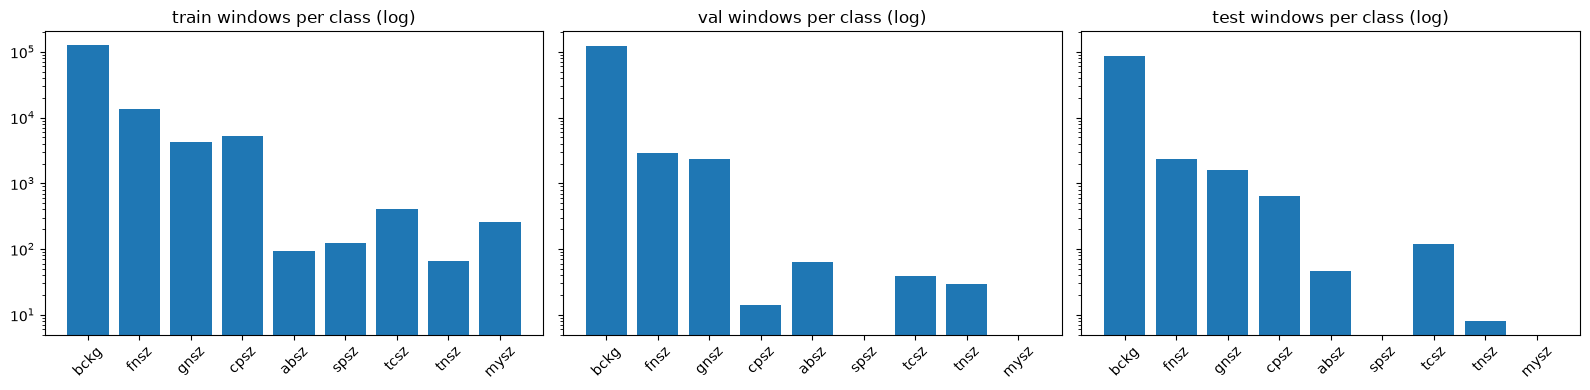

In [12]:
cls_tab = REC.groupby("split")[ccols].sum().reindex(["train", "val", "test"])
cls_tab.columns = [CLASS_NAMES[int(c[1:])] if int(c[1:]) < N_CLASSES else f"UNEXPECTED_{c[1:]}" for c in cls_tab.columns]
cls_tab.loc["TOTAL"] = cls_tab.sum()
print("Number of classes (config):", N_CLASSES, "| classes present in any split:", int((cls_tab.loc["TOTAL"] > 0).sum()))
display(cls_tab)

pct = (cls_tab.div(cls_tab.sum(axis=1), axis=0) * 100).round(3)
print("Percent of windows per class:")
display(pct)

hrs = (cls_tab * DURATION / 3600).round(2)
print("Hours per class:")
display(hrs)

missing = {s: [c for c in cls_tab.columns if cls_tab.loc[s, c] == 0] for s in ["train", "val", "test"]}
print("Classes with ZERO windows per split (explains sklearn 'y_pred contains classes not in y_true'):", missing)

fig, axes = plt.subplots(1, 3, figsize=(16, 4), sharey=True)
for ax, s in zip(axes, ["train", "val", "test"]):
    if s in cls_tab.index:
        ax.bar(cls_tab.columns, cls_tab.loc[s].values)
        ax.set_yscale("log"); ax.set_title(f"{s} windows per class (log)"); ax.tick_params(axis="x", rotation=45)
plt.tight_layout(); plt.show()

## 7. Recordings with / without seizures, and skipped-file log

In [13]:
REC["seiz_windows"] = REC[[c for c in ccols if c != "c0"]].sum(axis=1)
g = REC.groupby("split").agg(recordings=("stem", "size"), with_seizure=("seiz_windows", lambda x: int((x > 0).sum())),
                             mean_windows=("n_windows", "mean"), max_windows=("n_windows", "max"))
g["seizure_window_frac_%"] = REC.groupby("split").apply(lambda d: 100 * d.seiz_windows.sum() / d.n_windows.sum())
display(g.round(3))

err = os.path.join(PROCESSED, "tusz-process-error-files.txt")
if os.path.exists(err):
    lines = [l.rstrip("\n").split("\t") for l in open(err) if l.strip()]
    E = pd.DataFrame(lines, columns=["split", "recording", "status"][:len(lines[0])])
    E["reason"] = E.status.str.replace(r"\[.*?\]", "[...]", regex=True).str.slice(0, 60)
    print(f"{len(E)} skipped/flagged recordings. Reasons:")
    display(E.groupby(["split", "reason"]).size().rename("count").reset_index())
else:
    print("no error log found at", err)

,recordings,with_seizure,mean_windows,max_windows,seizure_window_frac_%
split,,,,,
test,880,165,104.960,360,5.164
train,4929,715,30.472,344,15.906
val,1910,217,67.481,281,4.142


421 skipped/flagged recordings. Reasons:


,split,reason,count
0,train,no windows kept,115
1,train,recording shorter than one window,13
2,val,no windows kept,36
3,val,recording shorter than one window,257


## 8. Structure of the stored `.npy` files (random windows)

In [14]:
split = "train"
d, xs = list_pre(split)
xp = random.choice(xs)
X = np.load(xp, mmap_mode="r"); y = np.load(xp.replace("_X.npy", "_y.npy"))
print("File:", os.path.basename(xp))
print("X: shape", X.shape, "dtype", X.dtype, "-> (n_windows, n_channels, n_samples)")
print("y: shape", y.shape, "dtype", y.dtype, "| label counts:", dict(zip(*np.unique(y, return_counts=True))))
print("Window length =", X.shape[2], "samples =", X.shape[2] / FS, "s at", FS, "Hz")

w = np.random.randint(0, X.shape[0])
win = np.array(X[w])                                     # (16, T), volts
print(f"\nRandom window #{w}, label = {y[w]} ({CLASS_NAMES[y[w]] if y[w] < N_CLASSES else '?'})")
df_win = pd.DataFrame(win.T, columns=ELECTRODES)         # columns = bipolar channel names, rows = time samples
df_win.index.name = "sample"
print("First 5 samples, in volts (what is stored on disk):")
display(df_win.head())
print("Same window x SCALE_FACTOR (what the model sees):")
display((df_win * SCALE_FACTOR).head())

ch_stats = pd.DataFrame({"mean": df_win.mean(), "std": df_win.std(), "min": df_win.min(), "max": df_win.max()})
display((ch_stats * SCALE_FACTOR).round(3).rename(columns=lambda c: c + " (scaled)"))

File: aaaaascj_s008_t003_X.npy
X: shape (28, 16, 1000) dtype float32 -> (n_windows, n_channels, n_samples)
y: shape (28,) dtype int64 | label counts: {np.int64(0): np.int64(28)}
Window length = 1000 samples = 5.0 s at 200 Hz

Random window #21, label = 0 (bckg)
First 5 samples, in volts (what is stored on disk):


,FP1-F7,F7-T3,T3-T5,T5-O1,FP2-F8,F8-T4,T4-T6,T6-O2,FP1-F3,F3-C3,C3-P3,P3-O1,FP2-F4,F4-C4,C4-P4,P4-O2
sample,,,,,,,,,,,,,,,,
0,-0.000002,0.000005,1.124382e-05,0.000005,0.000014,7.096740e-08,0.000003,2.706110e-08,0.000004,0.000013,0.000003,-0.000001,0.000017,0.000004,5.087492e-07,-3.971322e-06
1,0.000017,0.000003,-2.843365e-06,0.000011,0.000020,2.769229e-06,-0.000003,6.456307e-06,0.000007,0.000009,0.000004,0.000007,0.000018,0.000003,1.932568e-06,2.590701e-06
2,0.000014,-0.000004,2.166432e-07,0.000007,0.000017,-6.833272e-06,0.000007,8.146792e-06,0.000011,0.000005,0.000003,-0.000002,0.000014,0.000003,5.028392e-06,3.976611e-06
3,-0.000003,0.000009,8.736937e-06,0.000003,0.000018,-3.682764e-06,0.000003,4.634619e-06,0.000020,0.000014,-0.000004,-0.000012,0.000014,0.000005,4.781136e-06,-2.041182e-06
4,0.000016,0.000004,5.720453e-06,-0.000002,0.000016,4.835520e-06,-0.000006,6.851544e-06,0.000012,0.000009,0.000004,-0.000003,0.000013,0.000003,4.167178e-06,9.575549e-07


Same window x SCALE_FACTOR (what the model sees):


,FP1-F7,F7-T3,T3-T5,T5-O1,FP2-F8,F8-T4,T4-T6,T6-O2,FP1-F3,F3-C3,C3-P3,P3-O1,FP2-F4,F4-C4,C4-P4,P4-O2
sample,,,,,,,,,,,,,,,,
0,-0.016861,0.046272,0.112438,0.050759,0.144735,0.000710,0.029142,0.000271,0.043183,0.128940,0.032221,-0.011737,0.169453,0.040031,0.005087,-0.039713
1,0.165464,0.031822,-0.028434,0.112287,0.198249,0.027692,-0.028286,0.064563,0.071889,0.091224,0.044306,0.073720,0.183966,0.033019,0.019326,0.025907
2,0.137877,-0.042937,0.002166,0.070770,0.166558,-0.068333,0.073318,0.081468,0.109099,0.045108,0.031660,-0.017990,0.135302,0.027659,0.050284,0.039766
3,-0.028997,0.094120,0.087369,0.028241,0.182701,-0.036828,0.025212,0.046346,0.196367,0.142340,-0.042802,-0.115173,0.139496,0.050536,0.047811,-0.020412
4,0.155804,0.037098,0.057205,-0.021029,0.156476,0.048355,-0.063672,0.068515,0.121012,0.092406,0.043379,-0.027720,0.128928,0.029499,0.041672,0.009576


,mean (scaled),std (scaled),min (scaled),max (scaled)
FP1-F7,-0.037,0.286,-0.600,1.727
F7-T3,0.000,0.107,-0.450,0.435
T3-T5,-0.000,0.121,-0.571,0.452
T5-O1,-0.000,0.045,-0.178,0.152
FP2-F8,-0.037,0.282,-0.511,1.654
F8-T4,-0.007,0.068,-0.225,0.329
T4-T6,-0.001,0.055,-0.204,0.156
T6-O2,-0.001,0.048,-0.176,0.137
FP1-F3,-0.026,0.219,-0.452,1.324
F3-C3,-0.008,0.082,-0.257,0.505


## 9. Amplitude / NaN sanity check (relevant for NaN losses in fine-tuning)

,windows,std_median,std_p99,max_abs_median,max_abs_p99,max_abs_max,pct_over_clip,pct_over_20,nan,inf,windows_with_flat_channel
split,,,,,,,,,,,
test,1179,0.118,9.313000,0.726,81.473000,191.774002,0.679,2.799,0,0,0
train,1009,0.112,27.285999,0.679,132.164993,186.578995,1.586,5.451,0,0,0
val,1174,0.130,28.753000,0.655,128.593994,161.018005,1.618,2.385,0,0,0


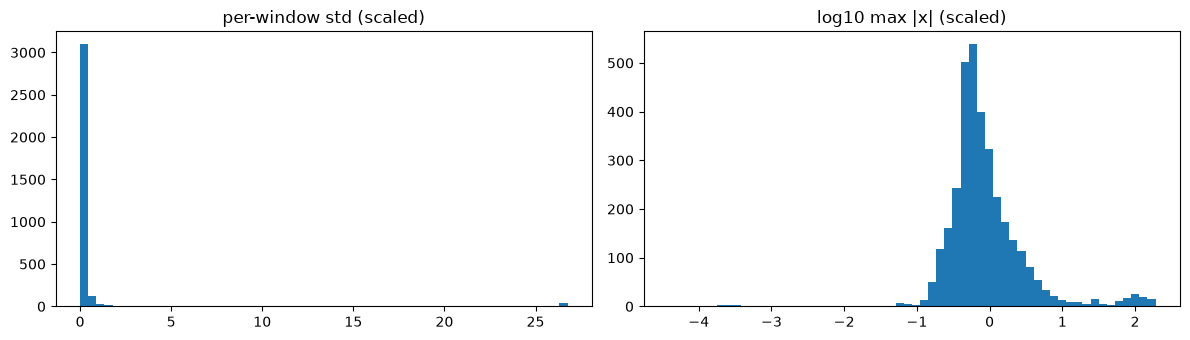

In [15]:
N_FILES, N_WIN = 60, 20          # sample size
rows = []
for split in ["train", "val", "test"]:
    d, xs = list_pre(split)
    for xp in random.sample(xs, min(N_FILES, len(xs))):
        X = np.load(xp, mmap_mode="r")
        idx = np.random.choice(X.shape[0], min(N_WIN, X.shape[0]), replace=False)
        for i in idx:
            w = np.array(X[i]) * SCALE_FACTOR
            rows.append(dict(split=split, std=w.std(), max_abs=np.abs(w).max(),
                             n_nan=int(np.isnan(w).sum()), n_inf=int(np.isinf(w).sum()),
                             flat_ch=int((w.std(axis=1) < 1e-6).sum())))
Q = pd.DataFrame(rows)
display(Q.groupby("split").agg(windows=("std", "size"), std_median=("std", "median"), std_p99=("std", lambda x: x.quantile(.99)),
                               max_abs_median=("max_abs", "median"), max_abs_p99=("max_abs", lambda x: x.quantile(.99)),
                               max_abs_max=("max_abs", "max"),
                               pct_over_clip=("max_abs", lambda x: 100 * (x > CLIP).mean()),
                               pct_over_20=("max_abs", lambda x: 100 * (x > 20).mean()),
                               nan=("n_nan", "sum"), inf=("n_inf", "sum"), windows_with_flat_channel=("flat_ch", lambda x: int((x > 0).sum()))).round(3))

fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
ax[0].hist(Q["std"].clip(upper=Q["std"].quantile(.99)), bins=60); ax[0].set_title("per-window std (scaled)")
ax[1].hist(np.log10(Q["max_abs"] + 1e-9), bins=60); ax[1].set_title("log10 max |x| (scaled)")
plt.tight_layout(); plt.show()

## 10. Visualize windows (background vs. each seizure class)

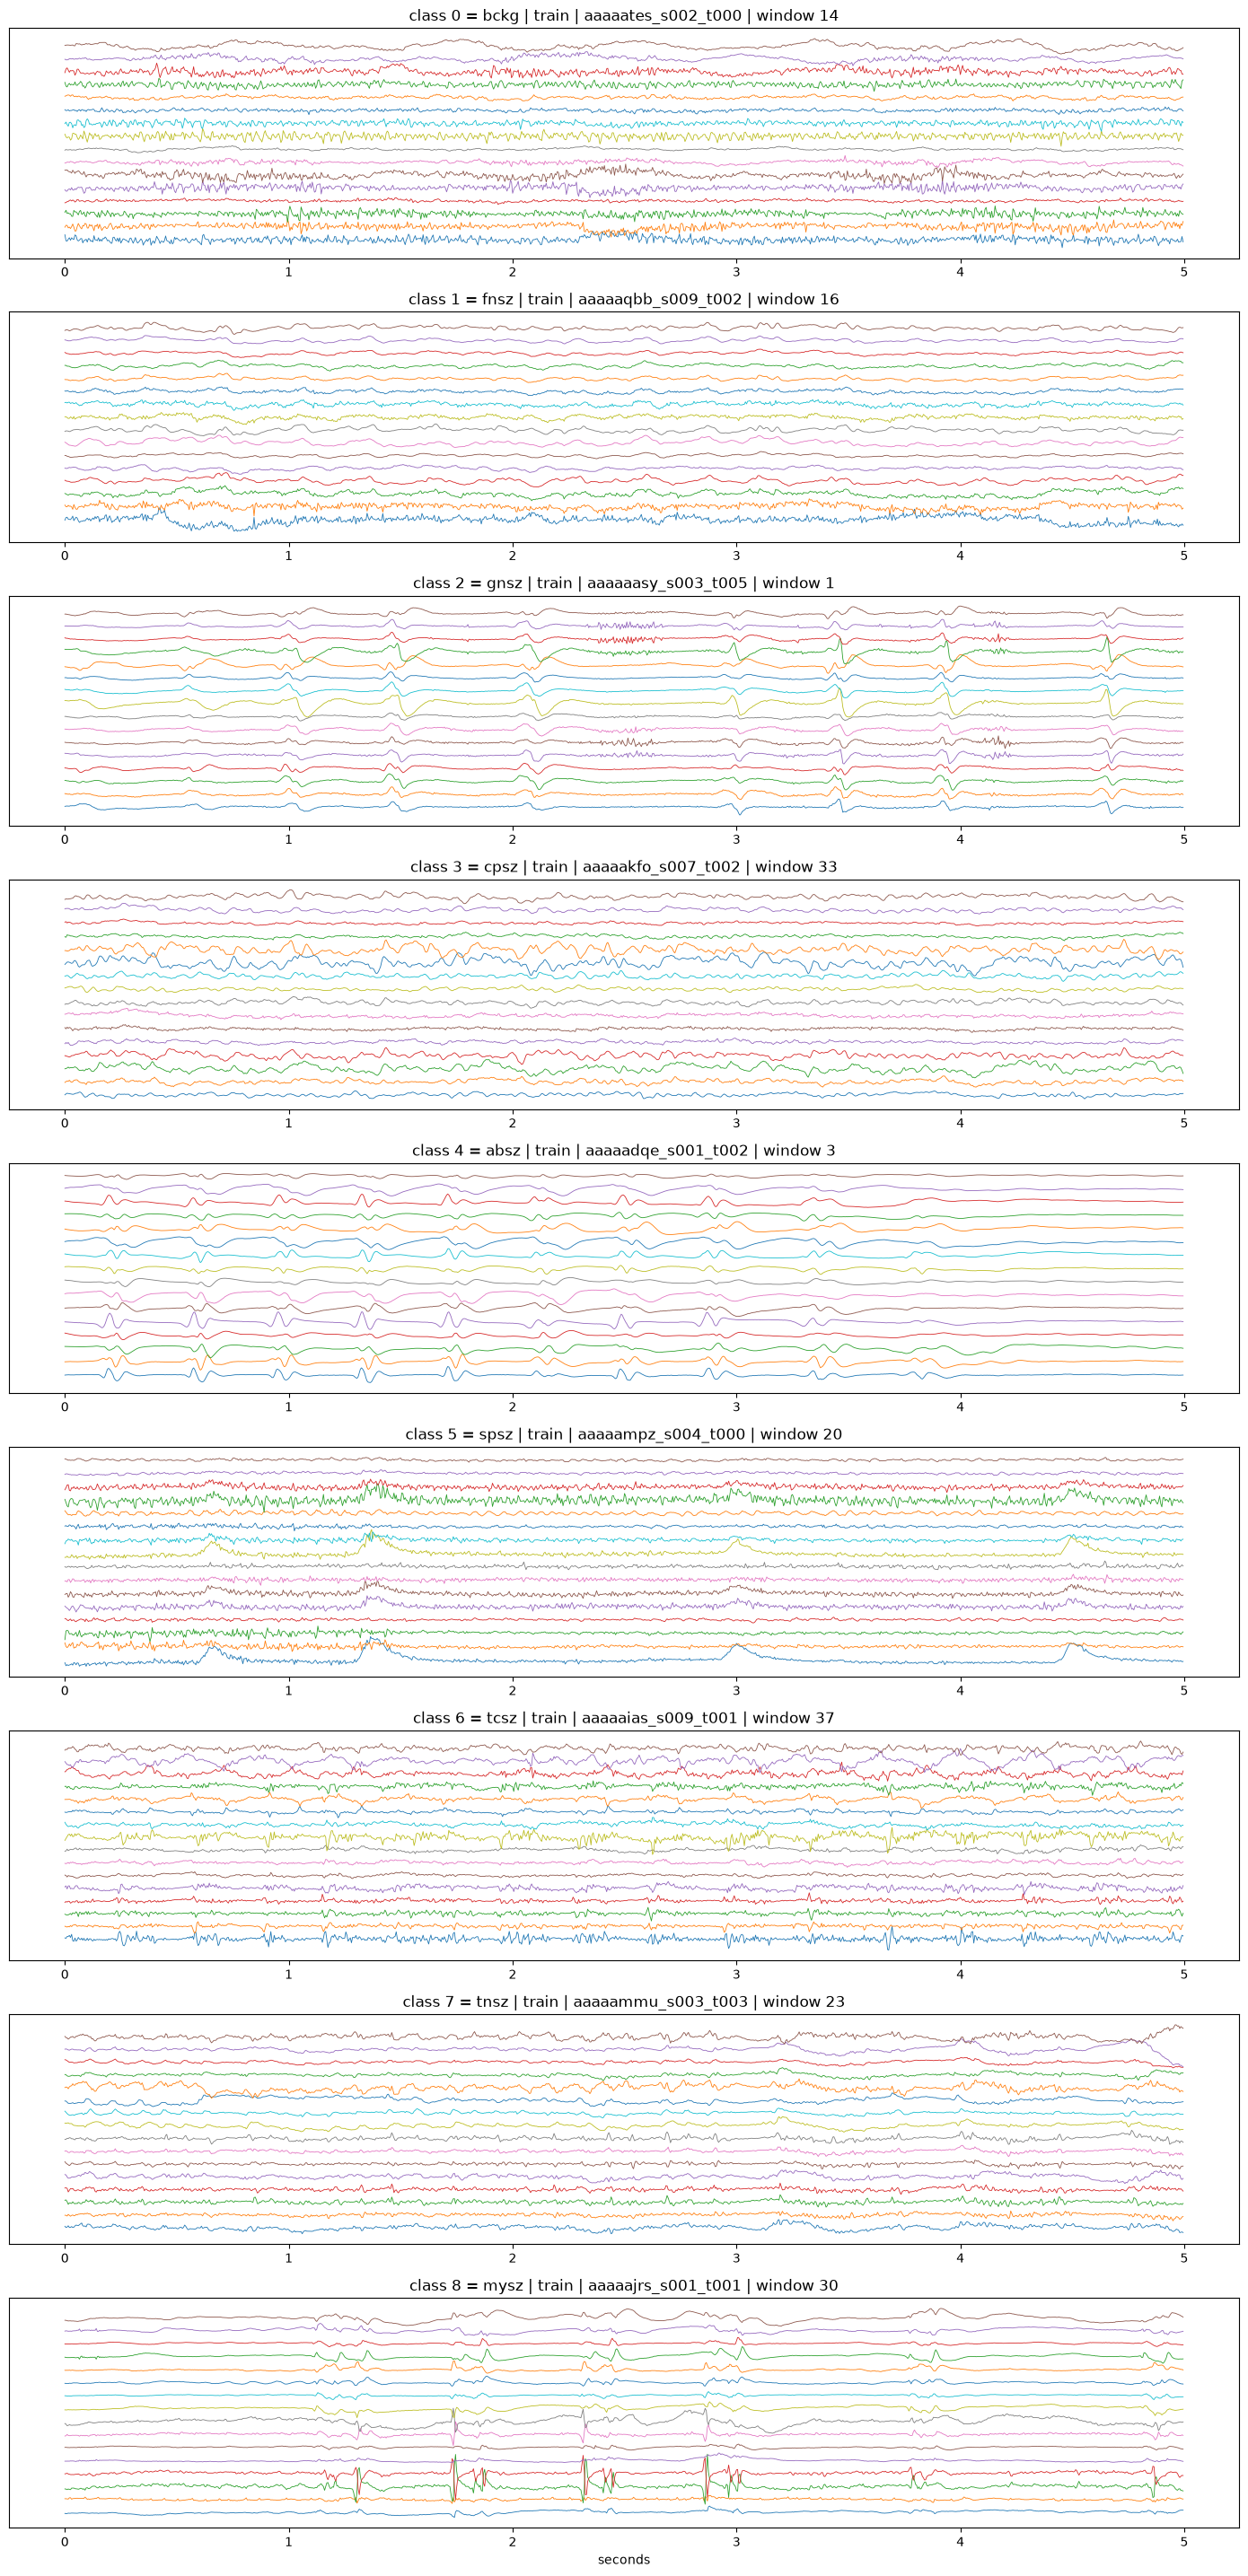

In [16]:
def get_window_of_class(c, tries=400):
    for split in ["train", "val", "test"]:
        d, xs = list_pre(split)
        pool = REC[(REC.split == split) & (REC.get(f"c{c}", 0) > 0)]
        if len(pool):
            row = pool.sample(1).iloc[0]
            xp = os.path.join(d, row.stem + "_X.npy")
            y = np.load(xp.replace("_X.npy", "_y.npy"))
            i = np.random.choice(np.where(y == c)[0])
            return split, row.stem, i, np.array(np.load(xp, mmap_mode="r")[i])
    return None

present = [c for c in range(N_CLASSES) if f"c{c}" in REC and REC[f"c{c}"].sum() > 0]
fig, axes = plt.subplots(len(present), 1, figsize=(14, 3.2 * len(present)), squeeze=False)
t = np.arange(DURATION * FS) / FS
for ax, c in zip(axes[:, 0], present):
    r = get_window_of_class(c)
    if r is None: continue
    split, stem, i, w = r
    w = w * SCALE_FACTOR
    for k in range(w.shape[0]):
        ax.plot(t, w[k] + k * 1.5 * max(w.std(), 1e-3) * 4, lw=0.6)
    ax.set_yticks([]); ax.set_title(f"class {c} = {CLASS_NAMES[c]} | {split} | {stem} | window {i}")
axes[-1, 0].set_xlabel("seconds")
plt.tight_layout(); plt.show()

## 11. Label timeline of one preprocessed recording

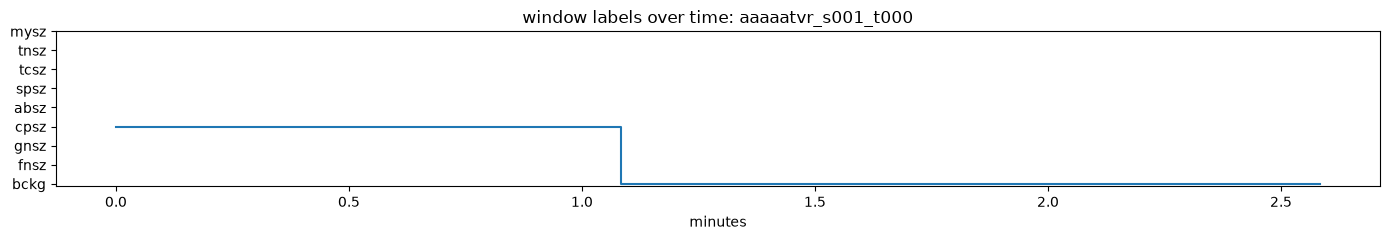

Raw annotation events for this recording:


,channel,start,stop,label,conf
0,FP1-F7,21.9398,65.3679,cpsz,1.0
1,T3-T5,21.9498,65.3946,cpsz,1.0
2,T5-O1,17.8595,65.3679,cpsz,1.0
4,F8-T4,17.8763,65.3679,cpsz,1.0
6,T6-O2,1.9565,65.3679,cpsz,1.0
10,P3-O1,4.4147,65.3679,cpsz,1.0
12,C4-P4,2.2575,65.3679,cpsz,1.0


In [17]:
pool = REC[(REC.split == "train") & (REC.seiz_windows > 0)]
row = pool.sample(1).iloc[0] if len(pool) else REC[REC.split == "train"].sample(1).iloc[0]
y = np.load(os.path.join(PROCESSED, "train", row.stem + "_y.npy"))
tt = np.arange(len(y)) * DURATION / 60
fig, ax = plt.subplots(figsize=(14, 2.5))
ax.step(tt, y, where="post"); ax.set_yticks(range(N_CLASSES)); ax.set_yticklabels(CLASS_NAMES)
ax.set_xlabel("minutes"); ax.set_title(f"window labels over time: {row.stem}")
plt.tight_layout(); plt.show()

# compare with raw annotation of the same recording
match = [e for e in RAW["train"] if os.path.basename(e)[:-4] == row.stem]
if match:
    a = read_ann(ann_path_for(match[0], ANN_EXT)).drop_duplicates(["start", "stop", "label"])
    print("Raw annotation events for this recording:")
    display(a)